# Ridge Regression on Bengaluru Dataset

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats

In [2]:
#Import Dataset
sales = pd.read_csv('Bengaluru_House_Data.csv')

In [3]:
sales.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [4]:
sales.shape

(13320, 9)

# Explainatory Data Analysis (EDA)

In [5]:
df = sales.copy()#Gives the copy of data

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [7]:
df.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


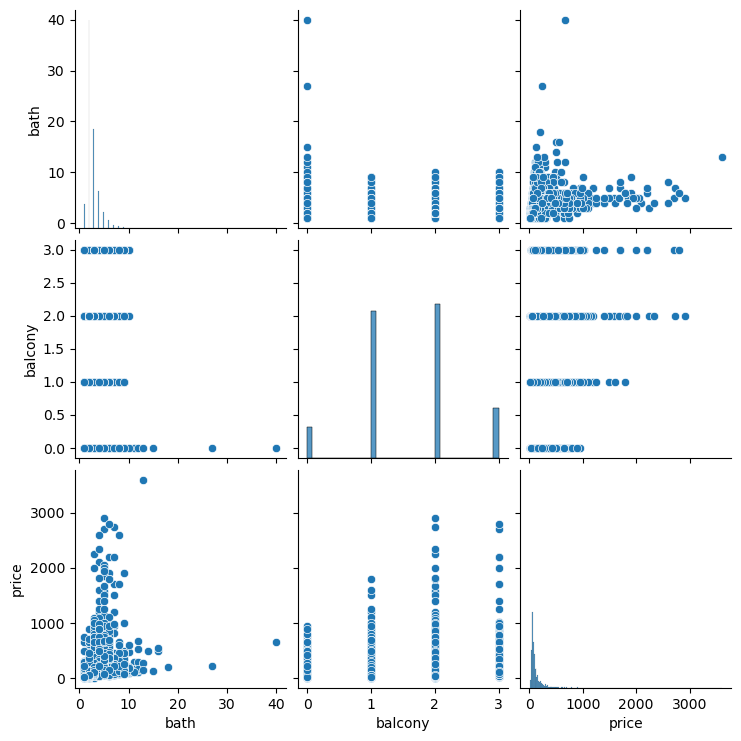

In [8]:
sns.pairplot(df)
# Bath and Price have slightly linear correlation with some outliers

In [9]:
# Value count of each feature
def value_count(df):
  for var in df.columns:
    print(df[var].value_counts())
    print("--------------------------------")

In [10]:
value_count(df).head()

area_type
Super built-up  Area    8790
Built-up  Area          2418
Plot  Area              2025
Carpet  Area              87
Name: count, dtype: int64
--------------------------------
availability
Ready To Move    10581
18-Dec             307
18-May             295
18-Apr             271
18-Aug             200
                 ...  
15-Aug               1
17-Jan               1
16-Nov               1
16-Jan               1
14-Jul               1
Name: count, Length: 81, dtype: int64
--------------------------------
location
Whitefield                        540
Sarjapur  Road                    399
Electronic City                   302
Kanakpura Road                    273
Thanisandra                       234
                                 ... 
Bapuji Layout                       1
1st Stage Radha Krishna Layout      1
BEML Layout 5th stage               1
singapura paradise                  1
Abshot Layout                       1
Name: count, Length: 1305, dtype: int64
-----------

AttributeError: 'NoneType' object has no attribute 'head'

## Correlation Heatmap

<Axes: >

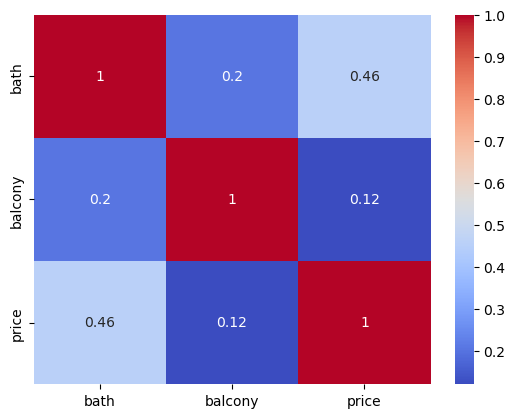

In [11]:
num_vars = ["bath", "balcony", "price"]
sns.heatmap(df[num_vars].corr(),cmap="coolwarm", annot=True)

# Correlation of Bath is greater than a Balcony with price

# Data Preaparation for ML Model

## Data Cleaning

In [12]:
df.isnull().sum() #To find how much missing data available

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

In [13]:
df.isnull().mean()*100 #To find % of missing data

#Society has 41.3% missing value so need to drop

area_type        0.000000
availability     0.000000
location         0.007508
size             0.120120
society         41.306306
total_sqft       0.000000
bath             0.548048
balcony          4.572072
price            0.000000
dtype: float64

In [14]:
df2 = df.drop('society', axis='columns')
df2.shape

(13320, 8)

In [15]:
#Will replace missing values of Balcony Feature by its mean
df2['balcony'] = df2['balcony'].fillna(df2['balcony'].mean())
df2.isnull().sum()

area_type        0
availability     0
location         1
size            16
total_sqft       0
bath            73
balcony          0
price            0
dtype: int64

In [16]:
#Will drop the missing values as it is very less.
df3 = df2.dropna()
df3.shape

(13246, 8)

In [17]:
df3.isnull().sum()

area_type       0
availability    0
location        0
size            0
total_sqft      0
bath            0
balcony         0
price           0
dtype: int64

In [18]:
df3.head()

,area_type,availability,location,size,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200,2.0,1.0,51.00


## Feature Engineering

In [19]:
# To show all the columns and rows
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)

In [20]:
df3['total_sqft'].value_counts().head()
#Variable 'total_sqft' is containing values in diffrent format.
#So best strategy would be to convert it into number.

total_sqft
1200    843
1100    221
1500    204
2400    195
600     180
Name: count, dtype: int64

In [21]:
total_sqft_int = []
for str_val in df3['total_sqft']:
  try:
    total_sqft_int.append(float(str_val)) # if '123.4' like this value in str then conver in float
  except:
    try:
      temp = []
      temp = str_val.split('-')
      total_sqft_int.append((float(temp[0])+float(temp[-1]))/2) # '123 - 534' this str value split and take mean
    except:
      total_sqft_int.append(np.nan) # if value not contain in above format then consider as nan

In [22]:
#Resetting the index of dataframe
df4 = df3.reset_index(drop=True)

In [23]:
# Join df4 and total_srft_int list
df5 = df4.join(pd.DataFrame({'total_sqft_int':total_sqft_int}))
df5.head()

,area_type,availability,location,size,total_sqft,bath,balcony,price,total_sqft_int
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056,2.0,1.0,39.07,1056.0
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600,5.0,3.0,120.00,2600.0
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440,2.0,3.0,62.00,1440.0
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521,3.0,1.0,95.00,1521.0
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200,2.0,1.0,51.00,1200.0


In [24]:
df5.isnull().sum()

area_type          0
availability       0
location           0
size               0
total_sqft         0
bath               0
balcony            0
price              0
total_sqft_int    46
dtype: int64

In [25]:
df6 = df5.dropna()
df6.shape

(13200, 9)

In [26]:
df6.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13200 entries, 0 to 13245
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   area_type       13200 non-null  object 
 1   availability    13200 non-null  object 
 2   location        13200 non-null  object 
 3   size            13200 non-null  object 
 4   total_sqft      13200 non-null  object 
 5   bath            13200 non-null  float64
 6   balcony         13200 non-null  float64
 7   price           13200 non-null  float64
 8   total_sqft_int  13200 non-null  float64
dtypes: float64(4), object(5)
memory usage: 1.0+ MB


In [27]:
df6.describe().round(2)

,bath,balcony,price,total_sqft_int
count,13200.00,13200.00,13200.00,13200.00
mean,2.69,1.59,112.28,1555.30
std,1.34,0.80,149.18,1237.32
min,1.00,0.00,8.00,1.00
25%,2.00,1.00,50.00,1100.00
50%,2.00,2.00,71.85,1275.00
75%,3.00,2.00,120.00,1672.00
max,40.00,3.00,3600.00,52272.00


In [28]:
#To get the number of rooms of each size
df6['size'].value_counts()

size
2 BHK         5192
3 BHK         4277
4 Bedroom      816
4 BHK          574
3 Bedroom      541
1 BHK          527
2 Bedroom      325
5 Bedroom      293
6 Bedroom      190
1 Bedroom      100
7 Bedroom       83
8 Bedroom       83
5 BHK           56
9 Bedroom       45
6 BHK           30
7 BHK           17
1 RK            13
10 Bedroom      12
9 BHK            7
8 BHK            5
11 BHK           2
11 Bedroom       2
10 BHK           2
14 BHK           1
13 BHK           1
12 Bedroom       1
27 BHK           1
43 Bedroom       1
16 BHK           1
19 BHK           1
18 Bedroom       1
Name: count, dtype: int64

In [29]:
size_int = []
for str_val in df6['size']:
  temp=[]
  temp = str_val.split(" ")
  try:
    size_int.append(int(temp[0]))
  except:
    size_int.append(np.nan)
    print("Noice = ",str_val)

In [30]:
df6 = df6.reset_index(drop=True)

In [31]:
# Join df6 and list size_int
df7 = df6.join(pd.DataFrame({'bhk':size_int}))
df7.shape

(13200, 10)

In [32]:
df7.head() 

,area_type,availability,location,size,total_sqft,bath,balcony,price,total_sqft_int,bhk
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056,2.0,1.0,39.07,1056.0,2
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600,5.0,3.0,120.00,2600.0,4
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440,2.0,3.0,62.00,1440.0,3
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521,3.0,1.0,95.00,1521.0,3
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200,2.0,1.0,51.00,1200.0,2


## Finding Outlier and Removing

In [33]:
# Function to create histogram, Q-Q plot and boxplot

# for Q-Q plots
import scipy.stats as stats

def diagnostic_plots(df, variable):
    plt.figure(figsize=(16, 4))

    # Histogram
    plt.subplot(1, 3, 1)
    sns.distplot(df[variable], bins=30)
    plt.title('Histogram')

    # Q-Q plot
    plt.subplot(1, 3, 2)
    stats.probplot(df[variable], dist="norm", plot=plt)
    plt.ylabel('Variable quantiles')

    # Boxplot
    plt.subplot(1, 3, 3)
    sns.boxplot(y=df[variable])
    plt.title('Boxplot')

    plt.show()

******* bath *******


C:\Users\Aditya\AppData\Local\Temp\ipykernel_15120\2621354737.py:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[variable], bins=30)


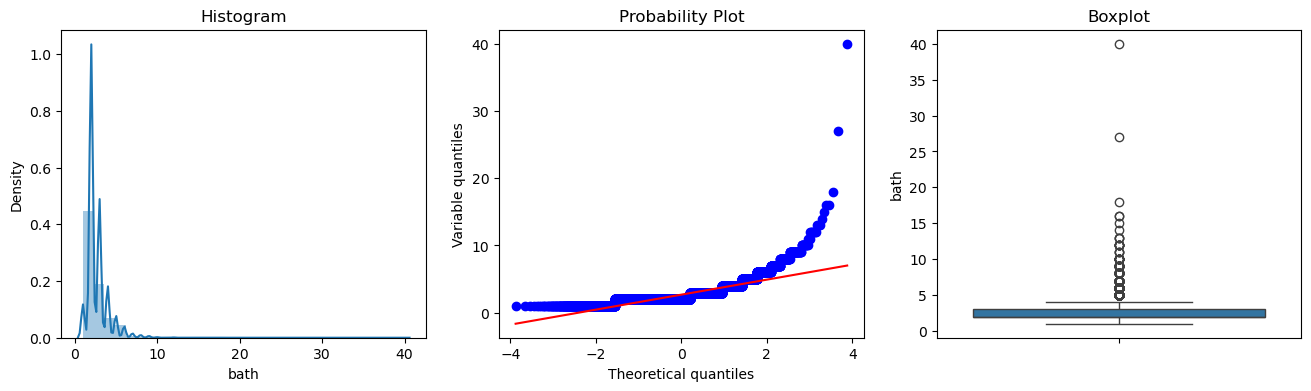

******* balcony *******


C:\Users\Aditya\AppData\Local\Temp\ipykernel_15120\2621354737.py:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[variable], bins=30)


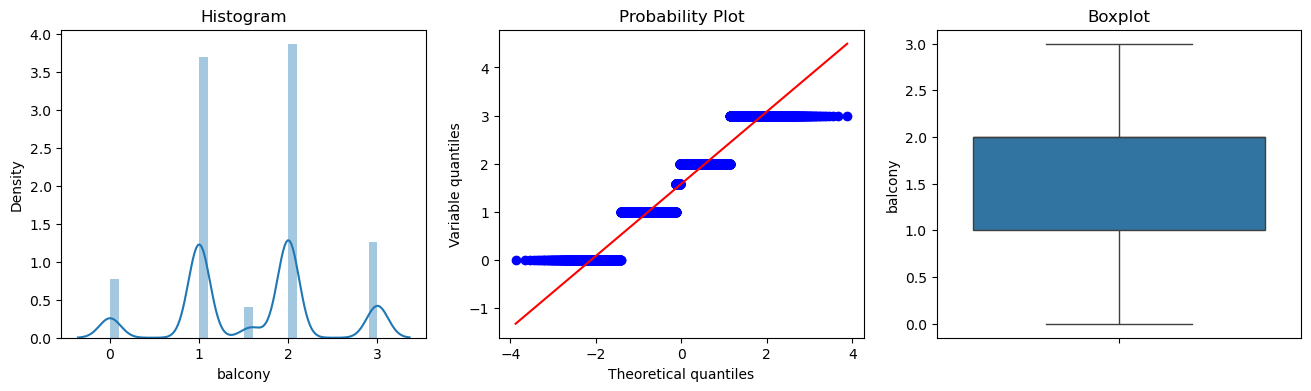

******* total_sqft_int *******


C:\Users\Aditya\AppData\Local\Temp\ipykernel_15120\2621354737.py:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[variable], bins=30)


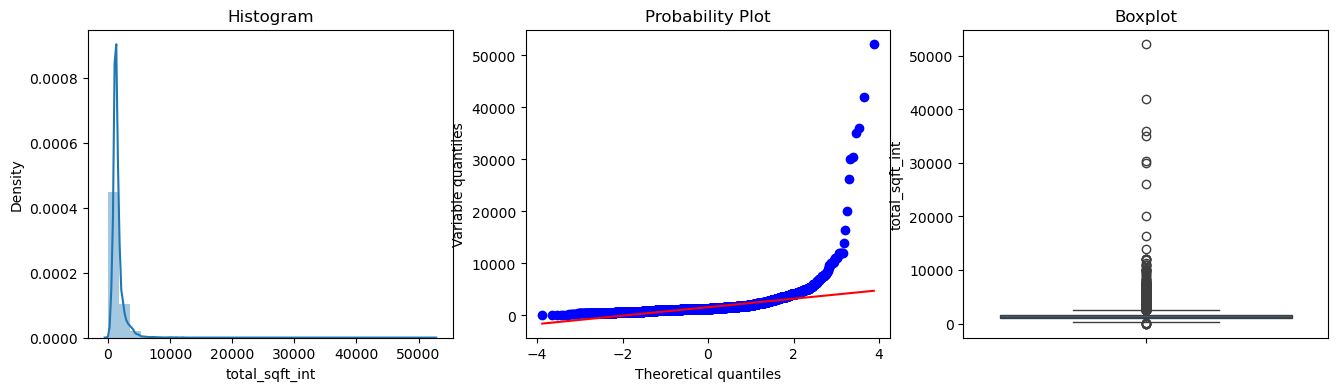

******* bhk *******


C:\Users\Aditya\AppData\Local\Temp\ipykernel_15120\2621354737.py:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[variable], bins=30)


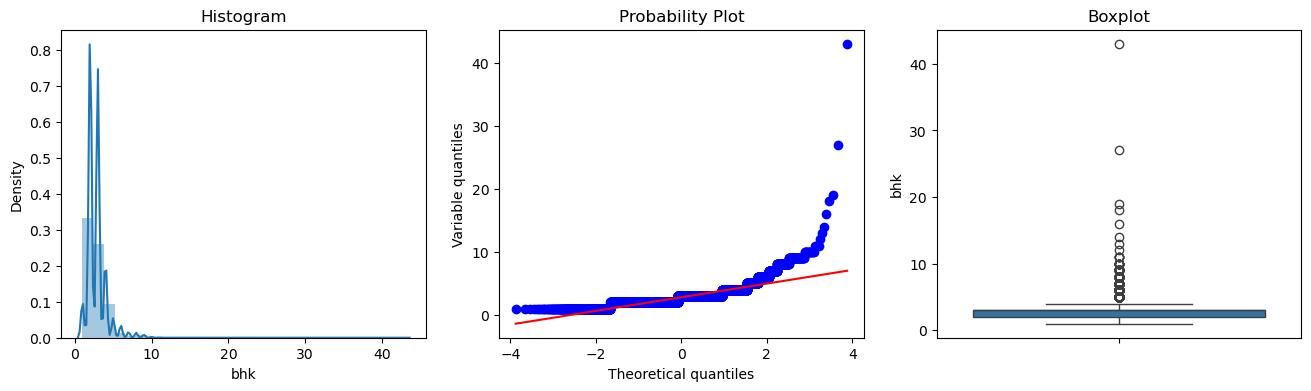

******* price *******


C:\Users\Aditya\AppData\Local\Temp\ipykernel_15120\2621354737.py:11: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[variable], bins=30)


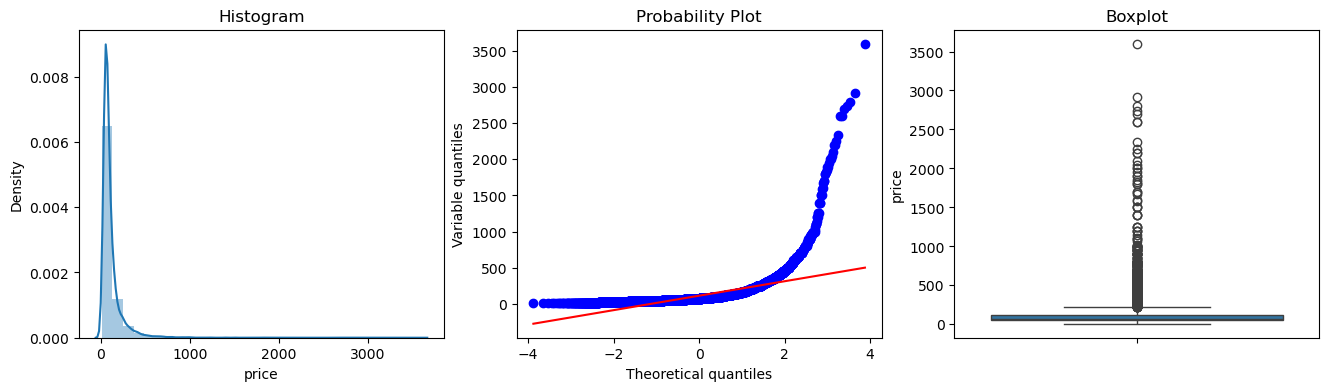

In [34]:
num_var = ["bath","balcony","total_sqft_int","bhk","price"]
for var in num_var:
  print("******* {} *******".format(var))
  diagnostic_plots(df7, var)

In [37]:
# If we consider 1 BHK requies min 350 sqft then
df7[df7['total_sqft_int']/df7['bhk'] < 350].head()

#Rows which are outlier

,area_type,availability,location,size,total_sqft,bath,balcony,price,total_sqft_int,bhk
9,Plot Area,Ready To Move,Gandhi Bazar,6 Bedroom,1020,6.0,1.584376,370.0,1020.0,6
26,Super built-up Area,Ready To Move,Electronic City,2 BHK,660,1.0,1.000000,23.1,660.0,2
29,Super built-up Area,Ready To Move,Electronic City,3 BHK,1025,2.0,1.000000,47.0,1025.0,3
45,Plot Area,Ready To Move,HSR Layout,8 Bedroom,600,9.0,1.584376,200.0,600.0,8
57,Plot Area,Ready To Move,Murugeshpalya,6 Bedroom,1407,4.0,1.000000,150.0,1407.0,6


In [38]:
# if 1 BHK total_sqft are < 350 then we'll remove above rows
df8 = df7[~(df7['total_sqft_int']/df7['bhk'] < 350)]
df8.shape

(12106, 10)

In [39]:
#Price is in lakhs so convert that into Rupee and divide by total_sqft_int
df8['price_per_sqft'] = df8['price']*100000 / df8['total_sqft_int']  
df8.head()

C:\Users\Aditya\AppData\Local\Temp\ipykernel_15120\4204048793.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df8['price_per_sqft'] = df8['price']*100000 / df8['total_sqft_int']


,area_type,availability,location,size,total_sqft,bath,balcony,price,total_sqft_int,bhk,price_per_sqft
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056,2.0,1.0,39.07,1056.0,2,3699.810606
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600,5.0,3.0,120.00,2600.0,4,4615.384615
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440,2.0,3.0,62.00,1440.0,3,4305.555556
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521,3.0,1.0,95.00,1521.0,3,6245.890861
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200,2.0,1.0,51.00,1200.0,2,4250.000000


In [40]:
df8.price_per_sqft.describe()

count     12106.000000
mean       6184.466889
std        4019.983503
min         267.829813
25%        4200.030048
50%        5261.108523
75%        6800.000000
max      176470.588235
Name: price_per_sqft, dtype: float64

In [41]:
# Removing outliers using help of 'price per sqrt'  taking std and mean per location
def remove_pps_outliers(df):
  df_out = pd.DataFrame()
  for key, subdf in df.groupby('location'):
    m=np.mean(subdf.price_per_sqft)
    st=np.std(subdf.price_per_sqft)
    reduced_df = subdf[(subdf.price_per_sqft>(m-st))&(subdf.price_per_sqft<=(m+st))]
    df_out = pd.concat([df_out, reduced_df], ignore_index = True)
  return df_out

df9 = remove_pps_outliers(df8)
df9.shape

(8888, 11)

In [42]:
def plot_scatter_chart(df,location):
  bhk2 = df[(df.location==location) & (df.bhk==2)]
  bhk3 = df[(df.location==location) & (df.bhk==3)]
  plt.figure(figsize=(16,9))
  plt.scatter(bhk2.total_sqft_int, bhk2.price, color='Blue', label='2 BHK', s=50)
  plt.scatter(bhk3.total_sqft_int, bhk3.price, color='Red', label='3 BHK', s=50, marker="+")
  plt.xlabel("Total Square Feet Area")
  plt.ylabel("Price")
  plt.title(location)
  plt.legend()

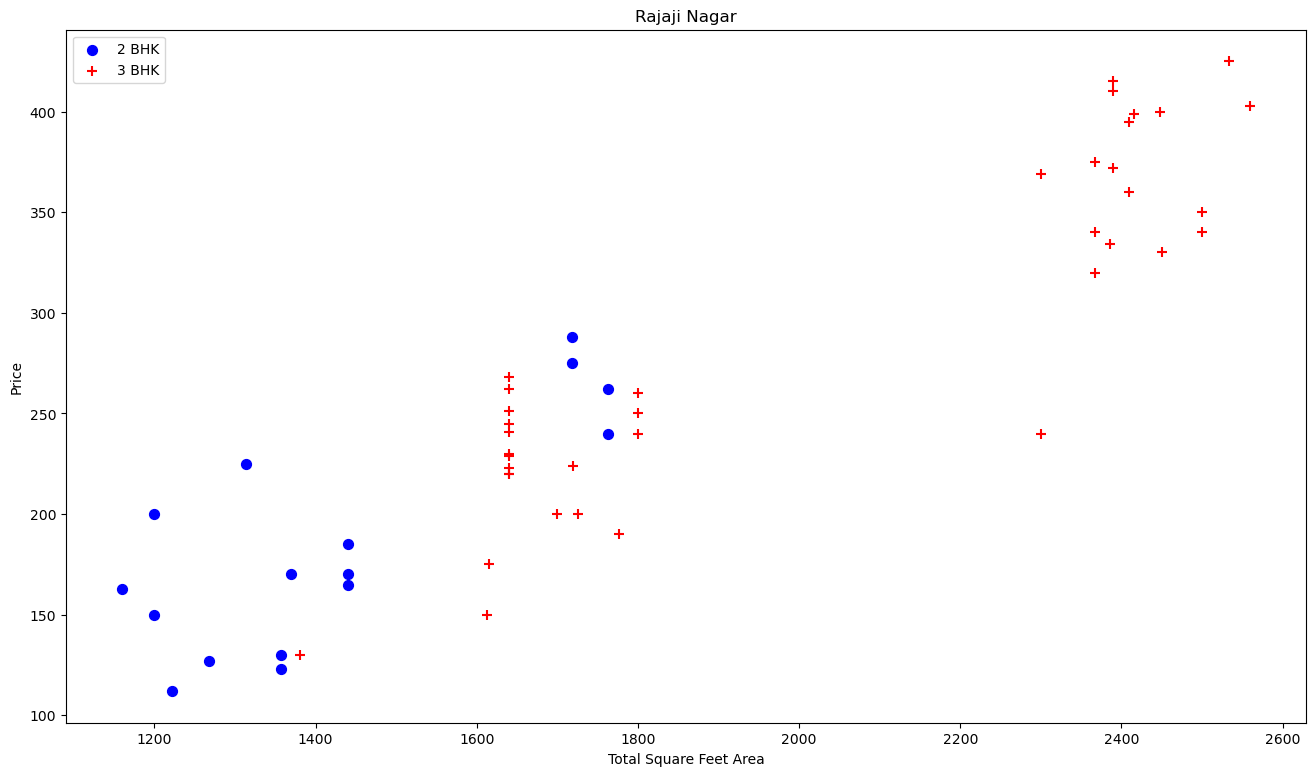

In [43]:
plot_scatter_chart(df9, "Rajaji Nagar")

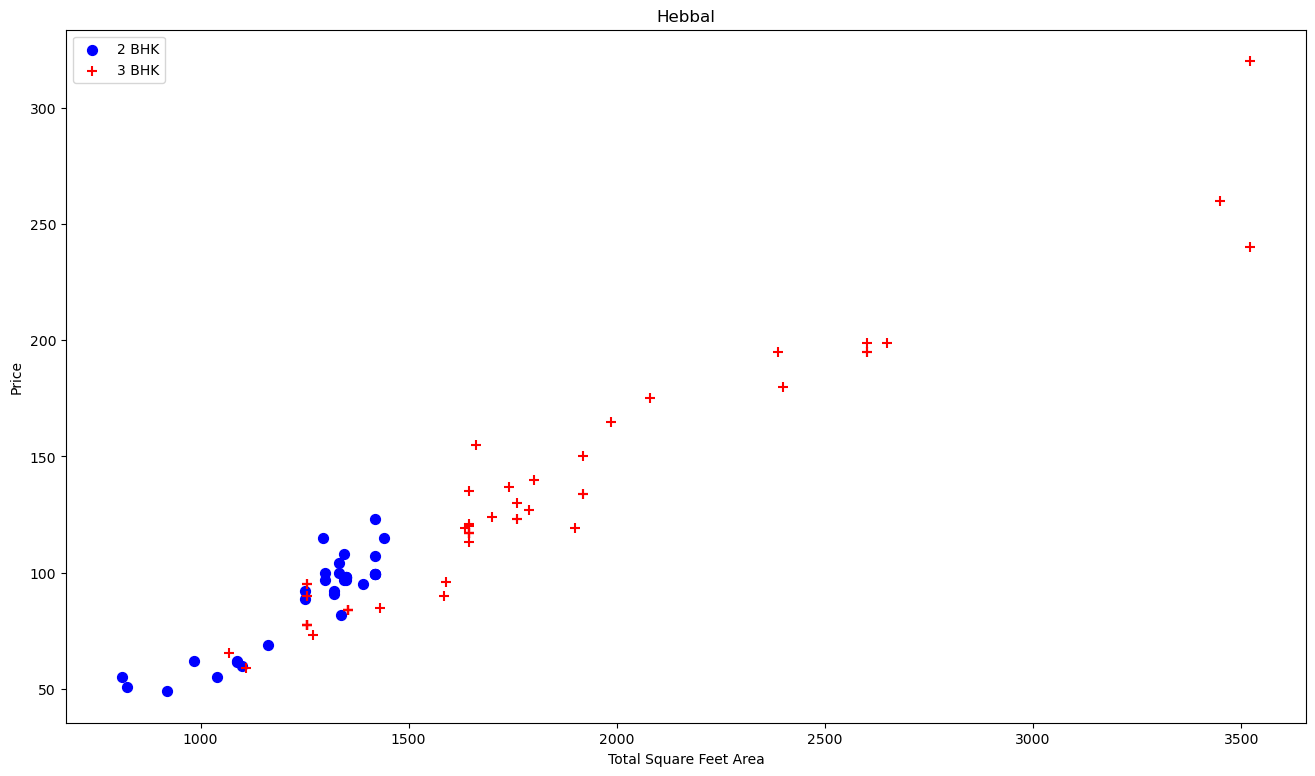

In [44]:
plot_scatter_chart(df9, "Hebbal")

In [45]:
# Removing BHK outliers
def remove_bhk_outliers(df):
  exclude_indices = np.array([])
  for location, location_df in df.groupby('location'):
    bhk_stats = {}
    for bhk, bhk_df in location_df.groupby('bhk'):
      bhk_stats[bhk]={
          'mean':np.mean(bhk_df.price_per_sqft),
          'std':np.std(bhk_df.price_per_sqft),
          'count':bhk_df.shape[0]}
    for bhk, bhk_df in location_df.groupby('bhk'):
      stats=bhk_stats.get(bhk-1)
      if stats and stats['count']>5:
        exclude_indices = np.append(exclude_indices, bhk_df[bhk_df.price_per_sqft<(stats['mean'])].index.values)
  return df.drop(exclude_indices, axis='index')

df10 = remove_bhk_outliers(df9)
df10.shape

(7194, 11)

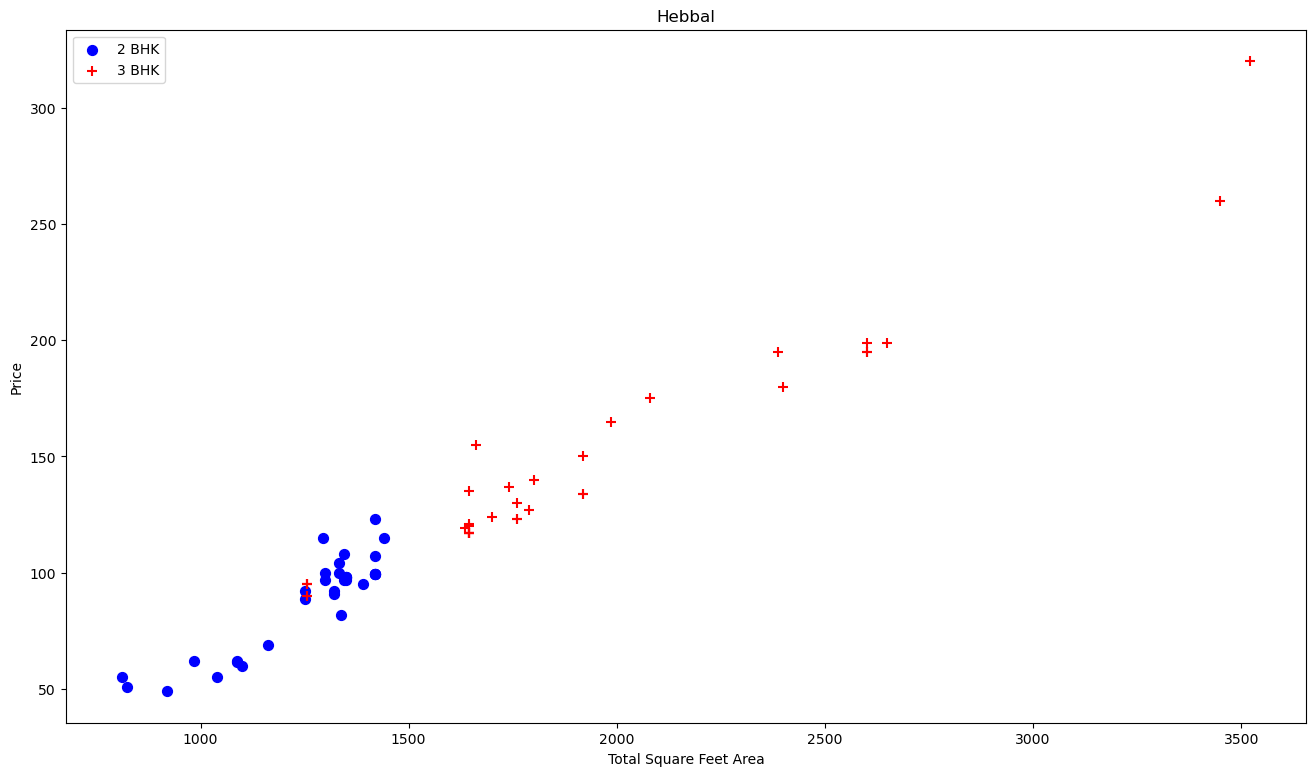

In [46]:
plot_scatter_chart(df10, "Hebbal")

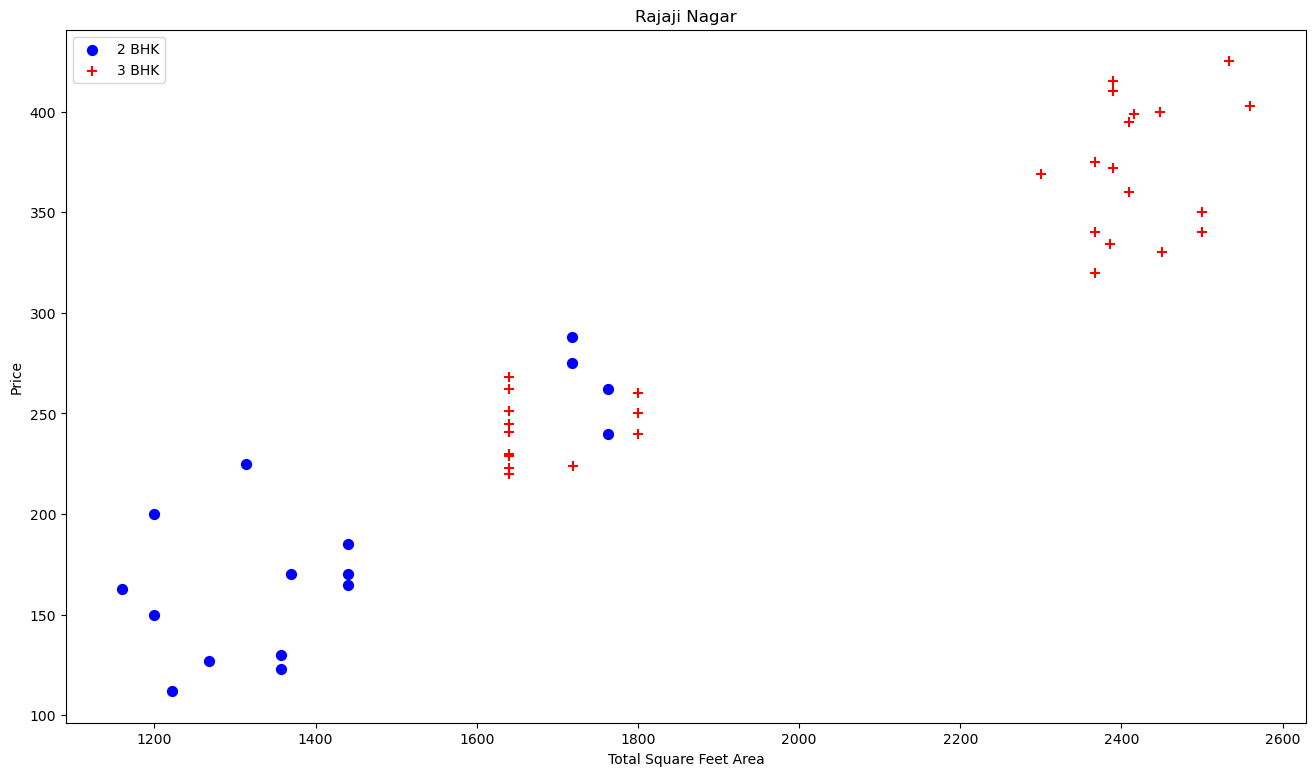

In [47]:
plot_scatter_chart(df10, "Rajaji Nagar")

## Removing Outliers using the help of 'bath' Feature


In [48]:
df10.bath.unique()

array([ 3.,  2.,  1.,  4.,  5.,  8.,  9.,  6.,  7., 12.])

In [49]:
df10[df10.bath > df10.bhk+2]

,area_type,availability,location,size,total_sqft,bath,balcony,price,total_sqft_int,bhk,price_per_sqft
1861,Built-up Area,Ready To Move,Chikkabanavar,4 Bedroom,2460,7.0,2.000000,80.0,2460.0,4,3252.032520
5836,Built-up Area,Ready To Move,Nagasandra,4 Bedroom,7000,8.0,1.584376,450.0,7000.0,4,6428.571429
7098,Super built-up Area,Ready To Move,Sathya Sai Layout,6 BHK,11338,9.0,1.000000,1000.0,11338.0,6,8819.897689
7569,Super built-up Area,Ready To Move,Thanisandra,3 BHK,1806,6.0,2.000000,116.0,1806.0,3,6423.034330


In [50]:
# Considering the data only with total number bathroom =  bhk + 2
df11 = df10[df10.bath < df10.bhk+2]
df11.shape

(7120, 11)

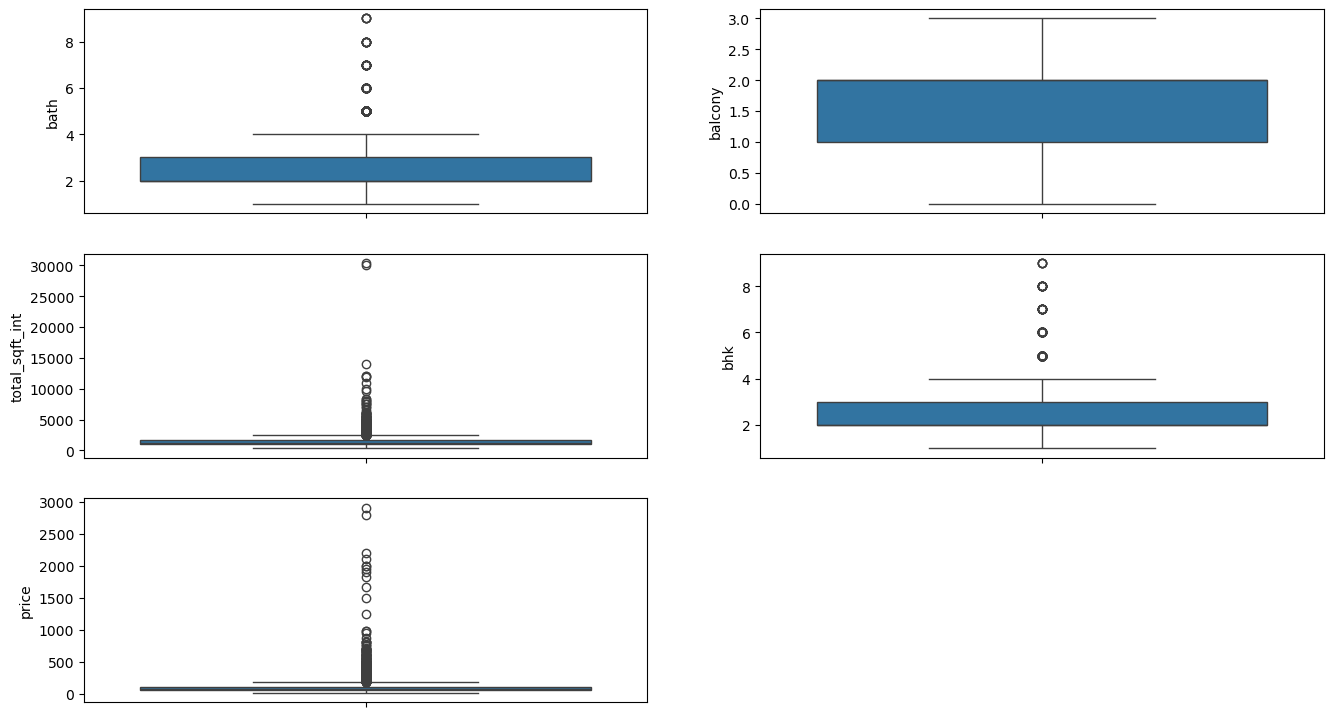

In [51]:
plt.figure(figsize=(16,9))
for i,var in enumerate(num_var):
  plt.subplot(3,2,i+1)
  sns.boxplot(df11[var])

In [52]:
df12 = df11.drop(['area_type', 'availability',"location","size","total_sqft"], axis =1)
df12.head()

,bath,balcony,price,total_sqft_int,bhk,price_per_sqft
0,3.0,2.0,150.0,1672.0,3,8971.291866
1,3.0,3.0,149.0,1750.0,3,8514.285714
2,3.0,2.0,150.0,1750.0,3,8571.428571
4,2.0,2.0,40.0,1250.0,2,3200.000000
5,2.0,2.0,83.0,1200.0,2,6916.666667


In [53]:
df12.isna().sum()

bath              0
balcony           0
price             0
total_sqft_int    0
bhk               0
price_per_sqft    0
dtype: int64

In [54]:
df12['balcony'].value_counts()

balcony
1.000000    2833
2.000000    2818
3.000000     803
0.000000     464
1.584376     202
Name: count, dtype: int64

In [55]:
df12.to_csv('Balcony.csv', index=False)

In [56]:
df12 = pd.read_csv('Balcony2.csv')
df12.head()

,bath,balcony,price,total_sqft_int,bhk,price_per_sqft
0,3,2,150.0,1672.0,3,8971.291866
1,3,3,149.0,1750.0,3,8514.285714
2,3,2,150.0,1750.0,3,8571.428571
3,2,2,40.0,1250.0,2,3200.000000
4,2,2,83.0,1200.0,2,6916.666667


In [57]:
df12['balcony'].value_counts()

balcony
1    2833
2    2818
3     803
0     464
Name: count, dtype: int64

## Categorical Variable Encoding

In [58]:
df13 = df11.drop(["size","total_sqft",'location'], axis =1)
df13.head()

,area_type,availability,bath,balcony,price,total_sqft_int,bhk,price_per_sqft
0,Super built-up Area,Ready To Move,3.0,2.0,150.0,1672.0,3,8971.291866
1,Built-up Area,Ready To Move,3.0,3.0,149.0,1750.0,3,8514.285714
2,Super built-up Area,Ready To Move,3.0,2.0,150.0,1750.0,3,8571.428571
4,Super built-up Area,Ready To Move,2.0,2.0,40.0,1250.0,2,3200.000000
5,Plot Area,Ready To Move,2.0,2.0,83.0,1200.0,2,6916.666667


In [59]:
df13['area_type'].value_counts(dropna=False)

area_type
Super built-up  Area    5345
Built-up  Area          1298
Plot  Area               441
Carpet  Area              36
Name: count, dtype: int64

In [60]:
df13.shape

(7120, 8)

In [61]:
df13.to_csv('Balcony3.csv', index=False)

In [62]:
df13 = pd.read_csv('Balcony4.csv')
df13.head()

,area_type,availability,bath,balcony,price,total_sqft_int,bhk,price_per_sqft
0,Super built-up Area,Ready To Move,3,2,150.0,1672.0,3,8971.291866
1,Built-up Area,Ready To Move,3,3,149.0,1750.0,3,8514.285714
2,Super built-up Area,Ready To Move,3,2,150.0,1750.0,3,8571.428571
3,Super built-up Area,Ready To Move,2,2,40.0,1250.0,2,3200.000000
4,Plot Area,Ready To Move,2,2,83.0,1200.0,2,6916.666667


In [63]:
df13['balcony'].value_counts()

balcony
1    2833
2    2818
3     803
0     464
Name: count, dtype: int64

In [64]:
# Perform one-hot encoding on 'area_type'
df14 = pd.get_dummies(df13, columns=['area_type'], prefix='area_type')

df14.head()

,availability,bath,balcony,price,total_sqft_int,bhk,price_per_sqft,area_type_Built-up Area,area_type_Carpet Area,area_type_Plot Area,area_type_Super built-up Area
0,Ready To Move,3,2,150.0,1672.0,3,8971.291866,False,False,False,True
1,Ready To Move,3,3,149.0,1750.0,3,8514.285714,True,False,False,False
2,Ready To Move,3,2,150.0,1750.0,3,8571.428571,False,False,False,True
3,Ready To Move,2,2,40.0,1250.0,2,3200.000000,False,False,False,True
4,Ready To Move,2,2,83.0,1200.0,2,6916.666667,False,False,True,False


In [65]:
df14['bhk'].value_counts()

bhk
2    3677
3    2334
1     440
4     363
5      55
6      29
7      10
8       7
9       3
Name: count, dtype: int64

In [66]:
df14.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6918 entries, 0 to 6917
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   availability                    6918 non-null   object 
 1   bath                            6918 non-null   int64  
 2   balcony                         6918 non-null   int64  
 3   price                           6918 non-null   float64
 4   total_sqft_int                  6918 non-null   float64
 5   bhk                             6918 non-null   int64  
 6   price_per_sqft                  6918 non-null   float64
 7   area_type_Built-up  Area        6918 non-null   bool   
 8   area_type_Carpet  Area          6918 non-null   bool   
 9   area_type_Plot  Area            6918 non-null   bool   
 10  area_type_Super built-up  Area  6918 non-null   bool   
dtypes: bool(4), float64(3), int64(3), object(1)
memory usage: 405.5+ KB


In [67]:
df14.isna().sum()

availability                      0
bath                              0
balcony                           0
price                             0
total_sqft_int                    0
bhk                               0
price_per_sqft                    0
area_type_Built-up  Area          0
area_type_Carpet  Area            0
area_type_Plot  Area              0
area_type_Super built-up  Area    0
dtype: int64

In [68]:
df15 = df14.copy()

In [69]:
df15.head()

,availability,bath,balcony,price,total_sqft_int,bhk,price_per_sqft,area_type_Built-up Area,area_type_Carpet Area,area_type_Plot Area,area_type_Super built-up Area
0,Ready To Move,3,2,150.0,1672.0,3,8971.291866,False,False,False,True
1,Ready To Move,3,3,149.0,1750.0,3,8514.285714,True,False,False,False
2,Ready To Move,3,2,150.0,1750.0,3,8571.428571,False,False,False,True
3,Ready To Move,2,2,40.0,1250.0,2,3200.000000,False,False,False,True
4,Ready To Move,2,2,83.0,1200.0,2,6916.666667,False,False,True,False


In [70]:
df15["availability_Ready To Move"] = np.where(df15["availability"]=="Ready To Move",1,0)
df15.shape

(6918, 12)

In [71]:
df15.head()

,availability,bath,balcony,price,total_sqft_int,bhk,price_per_sqft,area_type_Built-up Area,area_type_Carpet Area,area_type_Plot Area,area_type_Super built-up Area,availability_Ready To Move
0,Ready To Move,3,2,150.0,1672.0,3,8971.291866,False,False,False,True,1
1,Ready To Move,3,3,149.0,1750.0,3,8514.285714,True,False,False,False,1
2,Ready To Move,3,2,150.0,1750.0,3,8571.428571,False,False,False,True,1
3,Ready To Move,2,2,40.0,1250.0,2,3200.000000,False,False,False,True,1
4,Ready To Move,2,2,83.0,1200.0,2,6916.666667,False,False,True,False,1


## Drop Categorical Variable

In [72]:
df16 = df15.drop(["availability"], axis =1)
df16.shape

(6918, 11)

In [73]:
df16.head()

,bath,balcony,price,total_sqft_int,bhk,price_per_sqft,area_type_Built-up Area,area_type_Carpet Area,area_type_Plot Area,area_type_Super built-up Area,availability_Ready To Move
0,3,2,150.0,1672.0,3,8971.291866,False,False,False,True,1
1,3,3,149.0,1750.0,3,8514.285714,True,False,False,False,1
2,3,2,150.0,1750.0,3,8571.428571,False,False,False,True,1
3,2,2,40.0,1250.0,2,3200.000000,False,False,False,True,1
4,2,2,83.0,1200.0,2,6916.666667,False,False,True,False,1


In [74]:
df16.to_csv('ohe_data_reduce_cat_class.csv', index=False)
df16.head()

,bath,balcony,price,total_sqft_int,bhk,price_per_sqft,area_type_Built-up Area,area_type_Carpet Area,area_type_Plot Area,area_type_Super built-up Area,availability_Ready To Move
0,3,2,150.0,1672.0,3,8971.291866,False,False,False,True,1
1,3,3,149.0,1750.0,3,8514.285714,True,False,False,False,1
2,3,2,150.0,1750.0,3,8571.428571,False,False,False,True,1
3,2,2,40.0,1250.0,2,3200.000000,False,False,False,True,1
4,2,2,83.0,1200.0,2,6916.666667,False,False,True,False,1


In [75]:
df16.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6918 entries, 0 to 6917
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   bath                            6918 non-null   int64  
 1   balcony                         6918 non-null   int64  
 2   price                           6918 non-null   float64
 3   total_sqft_int                  6918 non-null   float64
 4   bhk                             6918 non-null   int64  
 5   price_per_sqft                  6918 non-null   float64
 6   area_type_Built-up  Area        6918 non-null   bool   
 7   area_type_Carpet  Area          6918 non-null   bool   
 8   area_type_Plot  Area            6918 non-null   bool   
 9   area_type_Super built-up  Area  6918 non-null   bool   
 10  availability_Ready To Move      6918 non-null   int64  
dtypes: bool(4), float64(3), int64(4)
memory usage: 405.5 KB


In [76]:
# df16['bhk'] = pd.to_numeric(df16['bhk'], errors='coerce')

In [77]:
# # Define bins and labels
# bins = [1, 2, 3, 4, float('inf')]  # Bin edges for values 1, 2, 3, and 4+
# labels = ['1', '2', '3', '4']

# # Create 'bhk_bin' column using cut
# df16['bhk_bin'] = pd.cut(df16['bhk'], bins=bins, labels=labels, right=False)

# # Count occurrences of each category
# bhk_bin_counts = df16['bhk_bin'].value_counts()

# print(bhk_bin_counts)

In [78]:
path = r"https://drive.google.com/uc?export=download&id=1P49POlAk27uRzWKXoR2WaEfb1lyyfiRJ"

In [79]:
#df = pd.read_csv(path)

# Linear Regression

In [80]:
df16['bath']= df16['bath'].astype(object)
df16['balcony']= df16['balcony'].astype(object)
df16['bhk']= df16['bhk'].astype(str)

In [81]:
df16.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6918 entries, 0 to 6917
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   bath                            6918 non-null   object 
 1   balcony                         6918 non-null   object 
 2   price                           6918 non-null   float64
 3   total_sqft_int                  6918 non-null   float64
 4   bhk                             6918 non-null   object 
 5   price_per_sqft                  6918 non-null   float64
 6   area_type_Built-up  Area        6918 non-null   bool   
 7   area_type_Carpet  Area          6918 non-null   bool   
 8   area_type_Plot  Area            6918 non-null   bool   
 9   area_type_Super built-up  Area  6918 non-null   bool   
 10  availability_Ready To Move      6918 non-null   int64  
dtypes: bool(4), float64(3), int64(1), object(3)
memory usage: 405.5+ KB


In [82]:
df16['balcony'].value_counts()

balcony
1    2833
2    2818
3     803
0     464
Name: count, dtype: int64

In [83]:
df16['bhk'].value_counts()

bhk
2    3677
3    2334
1     440
4     363
5      55
6      29
7      10
8       7
9       3
Name: count, dtype: int64

In [84]:
df16.isna().sum()

bath                              0
balcony                           0
price                             0
total_sqft_int                    0
bhk                               0
price_per_sqft                    0
area_type_Built-up  Area          0
area_type_Carpet  Area            0
area_type_Plot  Area              0
area_type_Super built-up  Area    0
availability_Ready To Move        0
dtype: int64

In [85]:
df18 = df16.copy()

In [86]:
# df18 = df18.drop(['balcony'], axis =1)
# df18.head()

In [87]:
df18['bath'].value_counts()

bath
2    4274
3    1609
1     482
4     389
5     118
6      26
7      12
8       6
9       2
Name: count, dtype: int64

In [88]:
X1 = df18.drop("price", axis=1)
y1 = df18['price']
print('Shape of X = ', X1.shape)
print('Shape of y = ', y1.shape)

Shape of X =  (6918, 10)
Shape of y =  (6918,)


In [89]:
X1.head()

,bath,balcony,total_sqft_int,bhk,price_per_sqft,area_type_Built-up Area,area_type_Carpet Area,area_type_Plot Area,area_type_Super built-up Area,availability_Ready To Move
0,3,2,1672.0,3,8971.291866,False,False,False,True,1
1,3,3,1750.0,3,8514.285714,True,False,False,False,1
2,3,2,1750.0,3,8571.428571,False,False,False,True,1
3,2,2,1250.0,2,3200.000000,False,False,False,True,1
4,2,2,1200.0,2,6916.666667,False,False,True,False,1


In [90]:
df18.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6918 entries, 0 to 6917
Data columns (total 11 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   bath                            6918 non-null   object 
 1   balcony                         6918 non-null   object 
 2   price                           6918 non-null   float64
 3   total_sqft_int                  6918 non-null   float64
 4   bhk                             6918 non-null   object 
 5   price_per_sqft                  6918 non-null   float64
 6   area_type_Built-up  Area        6918 non-null   bool   
 7   area_type_Carpet  Area          6918 non-null   bool   
 8   area_type_Plot  Area            6918 non-null   bool   
 9   area_type_Super built-up  Area  6918 non-null   bool   
 10  availability_Ready To Move      6918 non-null   int64  
dtypes: bool(4), float64(3), int64(1), object(3)
memory usage: 405.5+ KB


In [91]:
from sklearn.model_selection import train_test_split
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size = 0.25, random_state = 120)#test_size = ({0.2:(0.7827371794352629, 66.0715381035448)},{0.25:(0.7919583107238657, 60.784224605297695)},{0.3:(0.7992490054570138, 56.79358353731471)})
print('Shape of X1_train = ', X1_train.shape)
print('Shape of y1_train = ', y1_train.shape)
print('Shape of X1_test = ', X1_test.shape)
print('Shape of y1_test = ', y1_test.shape)

Shape of X1_train =  (5188, 10)
Shape of y1_train =  (5188,)
Shape of X1_test =  (1730, 10)
Shape of y1_test =  (1730,)


In [92]:
mean = np.mean(y1_train)
std_dev = np.std(y1_train)

print("Mean:", mean)
print("Standard Deviation:", std_dev)

Mean: 92.26846858134155
Standard Deviation: 107.20168294672874


In [93]:
mean = np.mean(y1_test)
std_dev = np.std(y1_test)

print("Mean:", mean)
print("Standard Deviation:", std_dev)

Mean: 92.48276300578034
Standard Deviation: 99.59665669761547


In [94]:
X1_train.head()

,bath,balcony,total_sqft_int,bhk,price_per_sqft,area_type_Built-up Area,area_type_Carpet Area,area_type_Plot Area,area_type_Super built-up Area,availability_Ready To Move
1629,3,2,3875.0,3,22296.774190,False,False,False,True,1
1978,2,1,1070.0,2,4485.981308,False,False,False,True,1
6040,3,3,1880.0,3,6382.978723,False,False,False,True,1
2225,2,1,1395.0,2,4558.422939,False,False,False,True,1
4661,2,2,1110.0,2,3693.693694,False,False,False,True,1


In [95]:
y1_train.head()

1629    864.00
1978     48.00
6040    120.00
2225     63.59
4661     41.00
Name: price, dtype: float64

In [96]:
X1_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5188 entries, 1629 to 1792
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   bath                            5188 non-null   object 
 1   balcony                         5188 non-null   object 
 2   total_sqft_int                  5188 non-null   float64
 3   bhk                             5188 non-null   object 
 4   price_per_sqft                  5188 non-null   float64
 5   area_type_Built-up  Area        5188 non-null   bool   
 6   area_type_Carpet  Area          5188 non-null   bool   
 7   area_type_Plot  Area            5188 non-null   bool   
 8   area_type_Super built-up  Area  5188 non-null   bool   
 9   availability_Ready To Move      5188 non-null   int64  
dtypes: bool(4), float64(2), int64(1), object(3)
memory usage: 304.0+ KB


In [97]:
X1_test.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1730 entries, 5341 to 4873
Data columns (total 10 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   bath                            1730 non-null   object 
 1   balcony                         1730 non-null   object 
 2   total_sqft_int                  1730 non-null   float64
 3   bhk                             1730 non-null   object 
 4   price_per_sqft                  1730 non-null   float64
 5   area_type_Built-up  Area        1730 non-null   bool   
 6   area_type_Carpet  Area          1730 non-null   bool   
 7   area_type_Plot  Area            1730 non-null   bool   
 8   area_type_Super built-up  Area  1730 non-null   bool   
 9   availability_Ready To Move      1730 non-null   int64  
dtypes: bool(4), float64(2), int64(1), object(3)
memory usage: 101.4+ KB


In [98]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Specify which features are continuous (by index)
continuous_feature_indices = [2,4]  # Replace with the indices of your continuous features

# Create a ColumnTransformer to apply transformations to specific columns
preprocessor = ColumnTransformer(
    transformers=[
        ('continuous', StandardScaler(), continuous_feature_indices)
        # You can add more transformers for other feature types if needed
    ],
    remainder='passthrough'  # Leave other columns unchanged
)

X_train_scaled = preprocessor.fit_transform(X1_train)
X_test_scaled = preprocessor.transform(X1_test)

In [99]:
X_test_scaled.shape

(1730, 10)

# Machine Learning Model Training(LR)

In [100]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import Ridge

In [101]:
lr1 = LinearRegression()

In [102]:
def rmse1(y1_test, y1_pred):
  return np.sqrt(mean_squared_error(y1_test, y1_pred))

In [103]:
lr1.fit(X_train_scaled, y1_train)
lr_score1 = lr1.score(X_test_scaled, y1_test)
lr_rmse1 = rmse1(y1_test, lr1.predict(X_test_scaled))
lr_score1, lr_rmse1

(0.8602571050153061, np.float64(37.231422372570734))

In [104]:
coef_dict_baseline = {}
for coef, feat in zip (lr1.coef_,X1_train.columns):
    coef_dict_baseline[feat] = coef
coef_dict_baseline

{'bath': np.float64(69.02320245178835),
 'balcony': np.float64(57.049294963502874),
 'total_sqft_int': np.float64(-1.9567027145952725),
 'bhk': np.float64(0.3982799144306818),
 'price_per_sqft': np.float64(-14.892728580541009),
 'area_type_Built-up  Area': np.float64(-0.6432649771805607),
 'area_type_Carpet  Area': np.float64(4.630469346371267),
 'area_type_Plot  Area': np.float64(-4.4365126196783615),
 'area_type_Super built-up  Area': np.float64(0.44930825048765477),
 'availability_Ready To Move': np.float64(-3.3028313913638296)}

In [105]:
lr1.fit(X_train_scaled,y1_train)
y1_pred = lr1.predict(X_test_scaled)

In [106]:
print(lr1.coef_)

[ 69.02320245  57.04929496  -1.95670271   0.39827991 -14.89272858
  -0.64326498   4.63046935  -4.43651262   0.44930825  -3.30283139]


In [107]:
print(lr1.intercept_)

135.2193489497161


In [108]:
print("R2_score",r2_score(y1_test,y1_pred))
print('RMSE',np.sqrt(mean_squared_error(y1_test,y1_pred)))

R2_score 0.8602571050153061
RMSE 37.231422372570734


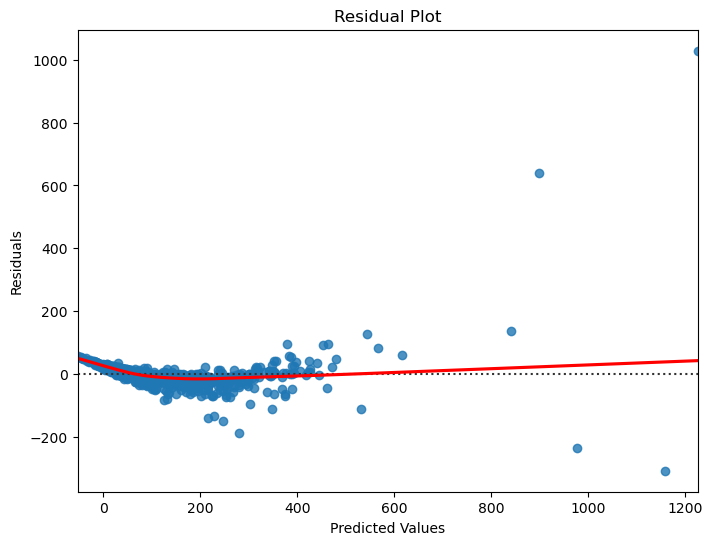

In [109]:
from sklearn.linear_model import LinearRegression
import numpy as np

# Assuming X1_train, y1_train, X1_test are your training data and testing data
# Create and fit the Linear Regression model
lr = LinearRegression()
lr.fit(X_train_scaled, y1_train)

# Predict y values using the model
y1_pred = lr.predict(X_test_scaled)

# Calculate residuals
residuals = y1_test - y1_pred

# Create a residual plot
plt.figure(figsize=(8, 6))
sns.residplot(x=y1_pred, y=residuals, lowess=True, line_kws={'color': 'red'})

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


# VIF

In [110]:
# Access column names of X_train dataset
feature_names_list = X1.columns

In [111]:
# Convert X_train to a pandas DataFrame and provide feature names
X1_train_df = pd.DataFrame(X1_train, columns=feature_names_list)

In [112]:
# # Filter out non-numeric columns
numeric_columns = X1_train_df.select_dtypes(include=['number']).columns

In [113]:
# Calculate VIF only for numeric columns
vif_data1 = pd.DataFrame()
vif_data1["Feature"] = numeric_columns
vif_data1["VIF"] = [variance_inflation_factor(X1_train_df[numeric_columns].values, i) for i in range(len(numeric_columns))]

print(vif_data1)

                      Feature       VIF
0              total_sqft_int  4.675273
1              price_per_sqft  5.587424
2  availability_Ready To Move  3.252280


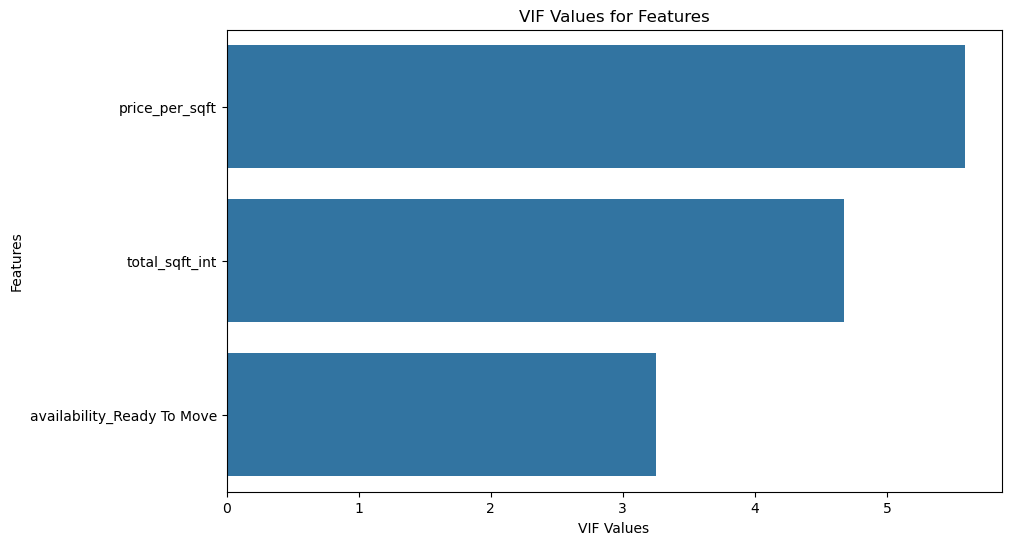

In [114]:
plt.figure(figsize=(10, 6))
sns.barplot(x="VIF", y="Feature", data=vif_data1.sort_values(by="VIF", ascending=False))
plt.xlabel("VIF Values")
plt.ylabel("Features")
plt.title("VIF Values for Features")
plt.show()

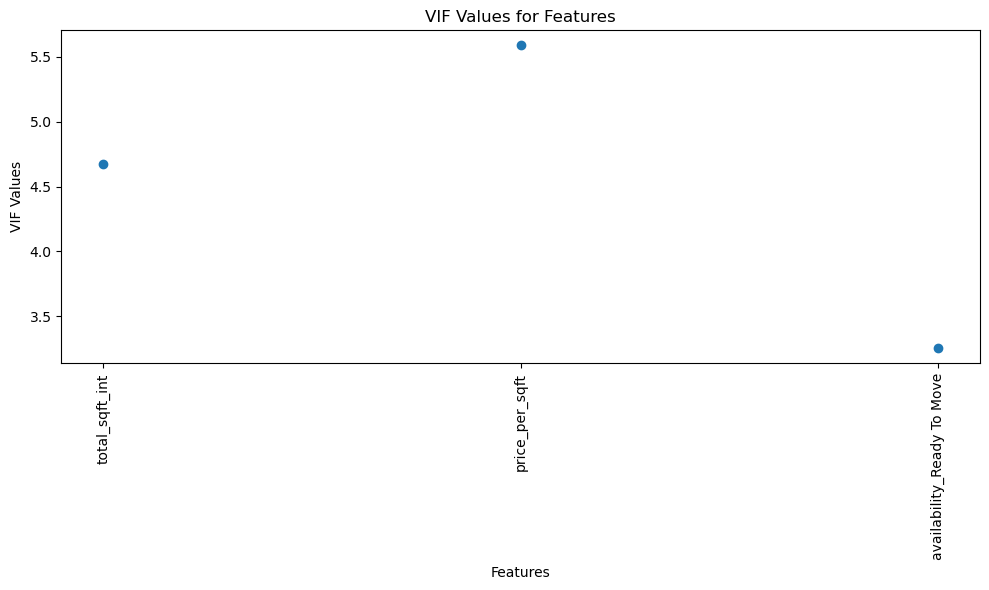

In [115]:
plt.figure(figsize=(10, 6))
plt.scatter(vif_data1["Feature"], vif_data1["VIF"])
plt.xticks(rotation=90)
plt.xlabel("Features")
plt.ylabel("VIF Values")
plt.title("VIF Values for Features")
plt.tight_layout()
plt.show()

# Ridge Regression without Location 

In [118]:
# Ridge
ridge_model1 = Ridge()
ridge_model1.fit(X_train_scaled, y1_train)
lr_ridge_score1=ridge_model1.score(X_test_scaled, y1_test)
y_ridge_pred1 = ridge_model1.predict(X_test_scaled)
lr_ridge_rmse1 = mean_squared_error(y1_test, y_ridge_pred1)
lr_ridge_score1, lr_ridge_rmse1

(0.8602756801117902, 1385.994556326166)

In [119]:
print(ridge_model1.coef_)
print(ridge_model1.intercept_)

[ 68.99651273  57.03968734  -1.9573933    0.39980158 -14.86397877
  -0.60084243   4.47106526  -4.36283194   0.4926091   -3.30081223]
135.10275439393578


# Ridge Regression without Location by taking alpha as 1.0

## Model Building

In [120]:
ridge_model2 = Ridge(alpha=1.0)

# Fit the model on the training data
ridge_model2.fit(X_train_scaled, y1_train)

# Get the coefficients and intercept
coefficients = ridge_model2.coef_
intercept = ridge_model2.intercept_

In [121]:
print('Coefficients of Ridge Model2',coefficients)
print('Intercept of Ridge Model2',intercept)

Coefficients of Ridge Model2 [ 68.99651273  57.03968734  -1.9573933    0.39980158 -14.86397877
  -0.60084243   4.47106526  -4.36283194   0.4926091   -3.30081223]
Intercept of Ridge Model2 135.10275439393578


### Coefficient Plot

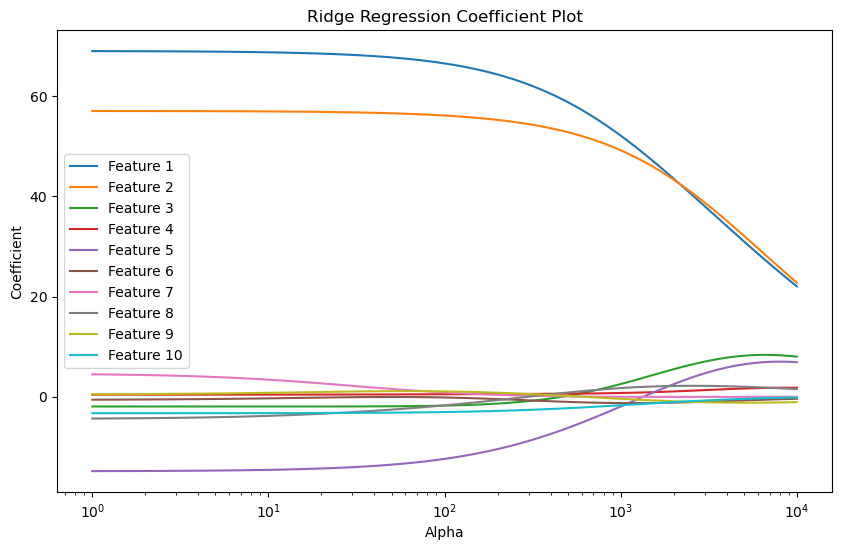

In [122]:
# Create a list of alpha values to test
alphas = np.logspace(0, 4, 100)

# Create an empty list to store the coefficients for each alpha
coefficients_list = []

# Iterate over the alpha values and fit Ridge Regression for each alpha
for alpha in alphas:
    ridge_model2 = Ridge(alpha=alpha)
    ridge_model2.fit(X_train_scaled, y1_train)
    coefficients_list.append(ridge_model2.coef_)

# Convert the coefficients list to a numpy array for plotting
coefficients_array = np.array(coefficients_list)

# Plot the coefficients against alpha
plt.figure(figsize=(10, 6))
for i in range(len(X1.columns)):
    plt.plot(alphas, coefficients_array[:, i], label=f'Feature {i+1}')

plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('Coefficient')
plt.legend()
plt.title('Ridge Regression Coefficient Plot')
plt.show()

### Hyperparameter Selection

In [123]:
# Ensure X1_train and y1_train are numpy arrays
X1_train = np.array(X1_train)
y1_train = np.array(y1_train)

In [124]:
from sklearn.model_selection import GridSearchCV

# Create a range of alpha values to test
alphas = np.logspace(0, 4, 100)

In [125]:
# Perform a grid search to find the best alpha value using cross-validation
param_grid = {'alpha': alphas}
ridge_model21 = Ridge()

In [126]:
grid_search = GridSearchCV(ridge_model21, param_grid, scoring='neg_mean_squared_error', cv=5)
# grid_search.fit(X1_train, y1_train)

In [127]:
grid_search.fit(X1_train, y1_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.",{'alpha': array([1.0000...00000000e+04])}
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- >2 : the score is also displayed;- >3 : the fold and candid

In [128]:
# Get the best alpha value
best_alpha = grid_search.best_params_['alpha']
best_alpha

np.float64(10000.0)

###  RMSE vs. Alpha Plot

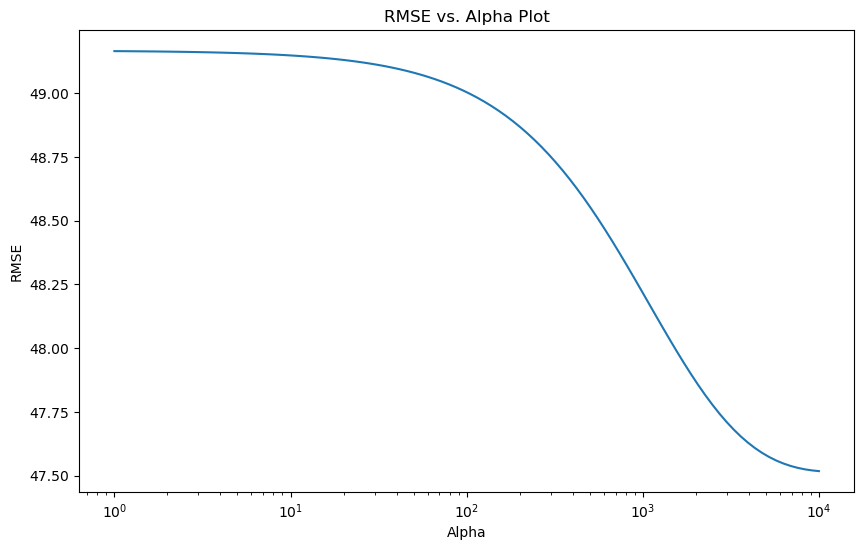

In [129]:


# Get the mean test scores from the grid search
mean_test_scores = np.sqrt(-grid_search.cv_results_['mean_test_score'])

# Plot the RMSE against alpha
plt.figure(figsize=(10, 6))
plt.plot(alphas, mean_test_scores)
plt.xscale('log')
plt.xlabel('Alpha')
plt.ylabel('RMSE')
plt.title('RMSE vs. Alpha Plot')
plt.show()

### Checking Assumptions

In [130]:
# Step 1: Get the model predictions on the training set
y_train_pred1 = ridge_model2.predict(X1_train)

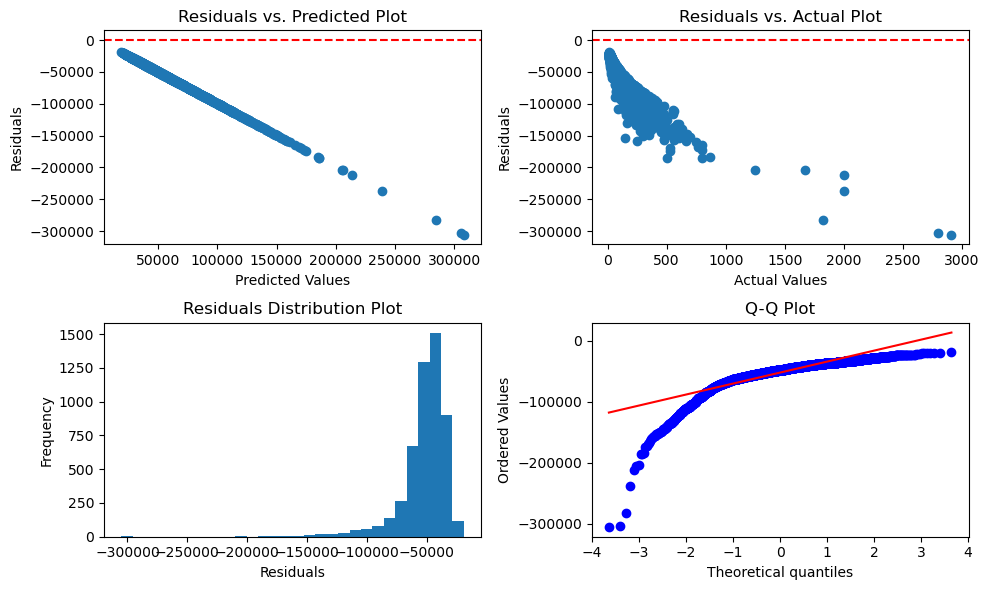

In [131]:
# Step 2: Calculate the residuals (the differences between actual and predicted values)
train_residuals1 = y1_train - y_train_pred1

# Step 3: Create residual plots
plt.figure(figsize=(10, 6))

# Residuals vs. Predicted Plot
plt.subplot(2, 2, 1)
plt.scatter(y_train_pred1, train_residuals1)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs. Predicted Plot')

# Residuals vs. Actual Plot
plt.subplot(2, 2, 2)
plt.scatter(y1_train, train_residuals1)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Actual Values')
plt.ylabel('Residuals')
plt.title('Residuals vs. Actual Plot')

# Residuals Distribution Plot
plt.subplot(2, 2, 3)
plt.hist(train_residuals1, bins=30)
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Residuals Distribution Plot')

# Q-Q Plot (Quantile-Quantile Plot)
from scipy.stats import probplot

plt.subplot(2, 2, 4)
probplot(train_residuals1, plot=plt)
plt.title('Q-Q Plot')

plt.tight_layout()
plt.show()

### Final Model Evaluation

In [132]:
# Finalize the Ridge Regression model with the best alpha value
final_ridge_model = Ridge(alpha=best_alpha)
final_ridge_model.fit(X1_train, y1_train)

# Evaluate the model on the test set
y1_pred = final_ridge_model.predict(X1_test)

# Calculate RMSE on the test set
from sklearn.metrics import mean_squared_error

test_rmse = np.sqrt(mean_squared_error(y1_test, y1_pred))
print(f"Test RMSE: {test_rmse}")


Test RMSE: 37.33208239684906


C:\Users\Aditya\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but Ridge was fitted without feature names
  warnings.warn(


In [133]:
# Calculate RMSE and R-squared on the test set
test_rmse = np.sqrt(mean_squared_error(y1_test, y1_pred))
test_r2 = r2_score(y1_test, y1_pred)
print(f"Test RMSE: {test_rmse}")
print(f"Test R-squared: {test_r2}")

Test RMSE: 37.33208239684906
Test R-squared: 0.859500457127703


## Bias Variance Tradeoff

In [134]:
# Step 8: Bias-Variance Tradeoff
# Assess the bias-variance tradeoff
train_predictions = final_ridge_model.predict(X1_train)
train_mse = mean_squared_error(y1_train, train_predictions)
train_variance = np.var(train_predictions)

print(f"Train MSE: {train_mse}")
print(f"Train Variance: {train_variance}")

Train MSE: 2064.6835991075664
Train Variance: 9390.729518392094


## Evaluate Test Performance

In [135]:
y_pred = final_ridge_model.predict(X1_test)
test_rmse = np.sqrt(mean_squared_error(y1_test, y1_pred))
print(f"Test RMSE: {test_rmse}")

Test RMSE: 37.33208239684906


C:\Users\Aditya\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but Ridge was fitted without feature names
  warnings.warn(


## Model Interpretation

# Ridge Regression without Location by taking alpha and Solvers

### Model Building 

In [136]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Ridge

# Create a range of alpha values to test
alphas = np.logspace(0, 4, 10)

# Define the solvers to be tested
solvers = ['auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga']

# Create a parameter grid to be tested
param_grid = {'alpha': alphas, 'solver': solvers}

# Create the Ridge Regression model
ridge_model3 = Ridge()

# Perform a grid search to find the best alpha value and solver using cross-validation
grid_search = GridSearchCV(ridge_model3, param_grid, scoring='neg_mean_squared_error', cv=5)
grid_search.fit(X1_train, y1_train)

# Get the best alpha value and solver
best_alpha = grid_search.best_params_['alpha']
best_solver = grid_search.best_params_['solver']

C:\Users\Aditya\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\Aditya\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\Aditya\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\Aditya\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\Aditya\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\Aditya\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max

C:\Users\adity\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\adity\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\adity\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\adity\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\adity\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\adity\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter 

C:\Users\adity\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\adity\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\adity\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\adity\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\adity\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
C:\Users\adity\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:350: ConvergenceWarning: The max_iter 

In [137]:
best_alpha

np.float64(10000.0)

In [138]:
best_solver

'auto'

# Ridge Regression Model Building with Best Hyperparameters

In [139]:
# Finalize the Ridge Regression model with the best alpha and solver values
final_ridge_model1 = Ridge(alpha=best_alpha, solver=best_solver)
final_ridge_model1.fit(X1_train, y1_train)

,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",np.float64(10000.0)
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average G

###  Final Model Evaluation

In [140]:
# Evaluate the model on the test set
y2_pred = final_ridge_model1.predict(X1_test)

# Calculate RMSE on the test set
from sklearn.metrics import mean_squared_error

test_rmse = np.sqrt(mean_squared_error(y1_test, y2_pred))
print(f"Test RMSE: {test_rmse}")

Test RMSE: 37.33208239684906


C:\Users\Aditya\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2684: UserWarning: X has feature names, but Ridge was fitted without feature names
  warnings.warn(


# SVM

In [141]:
from sklearn.svm import SVC,SVR
from sklearn.decomposition import KernelPCA

In [142]:
# Step 3: Create and train the SVR model
svr_model = SVR(kernel='linear')  # Linear kernel
svr_model.fit(X_train_scaled, y1_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [143]:
# Step 4: Make predictions
y_pred = svr_model.predict(X_test_scaled)

In [144]:
# Step 5: Calculate Mean Squared Error
mse = mean_squared_error(y1_test, y_pred)
print(f"Mean Squared Error: {mse:.2f}")

Mean Squared Error: 1904.61


In [145]:
RMSE = np.sqrt(mse)
RMSE

np.float64(43.641792194229154)

In [146]:
from sklearn.metrics import r2_score

# Calculate R-squared score
r_squared = r2_score(y1_test, y_pred)

print("R-squared score:", r_squared)


R-squared score: 0.8079936314233039


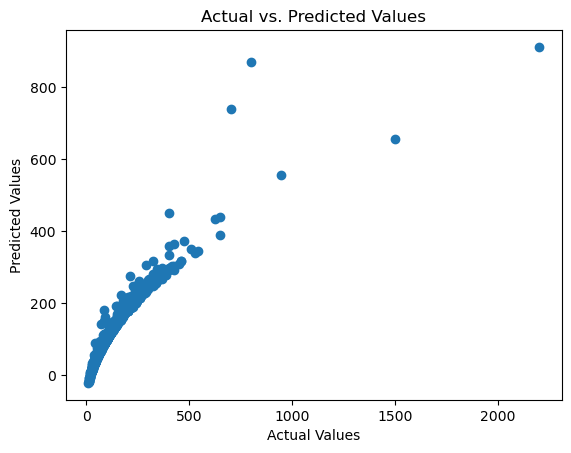

In [147]:
# Step 6: Visualize predicted vs. actual values (optional)
plt.scatter(y1_test, y_pred)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs. Predicted Values')
plt.show()

### Best Hyperparameters

In [148]:
# Define the parameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],  # Regularization parameter
    'gamma': [0.001, 0.01, 0.1, 1]  # Gamma parameter for RBF kernel
}

# Create an SVR model
svr = SVR(kernel='linear')

# Instantiate GridSearchCV
grid_search = GridSearchCV(svr, param_grid, scoring='neg_mean_squared_error', cv=5)

# Fit the grid search to the data
grid_search.fit(X_train_scaled, y1_train)

# Get the best hyperparameters
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)

# Get the best model
best_svr_model = grid_search.best_estimator_

# Make predictions
y_pred = best_svr_model.predict(X_test_scaled)

# Evaluate the model using Mean Squared Error
mse = mean_squared_error(y1_test, y_pred)
print("Mean Squared Error with Best Hyperparameters:", mse)

Best Hyperparameters: {'C': 100, 'gamma': 0.001}
Mean Squared Error with Best Hyperparameters: 1872.0032128439964


In [149]:
RMSE1 = np.sqrt(mse)
RMSE1

np.float64(43.26665243399351)

In [150]:
from sklearn.metrics import r2_score

# Calculate R-squared score
r_squared = r2_score(y1_test, y_pred)

print("R-squared score:", r_squared)

R-squared score: 0.8112803729644541


In [ ]:
# Define the parameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],  # Regularization parameter
    'gamma': [0.001, 0.01, 0.1, 1]  # Gamma parameter for poly kernel
}

# Create an SVR model
svr = SVR(kernel='poly')

# Instantiate GridSearchCV
grid_search = GridSearchCV(svr, param_grid, scoring='neg_mean_squared_error', cv=5)

# Fit the grid search to the data
grid_search.fit(X_train_scaled, y1_train)

# Get the best hyperparameters
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)

# Get the best model
best_svr_model = grid_search.best_estimator_

# Make predictions
y_pred = best_svr_model.predict(X_test_scaled)

# Evaluate the model using Mean Squared Error
mse = mean_squared_error(y1_test, y_pred)
print("Mean Squared Error with Best Hyperparameters:", mse)

In [ ]:
RMSE2 = np.sqrt(mse)
RMSE2

In [ ]:
# Define the parameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],  # Regularization parameter
    'gamma': [0.001, 0.01, 0.1, 1]  # Gamma parameter for RBF kernel
}

# Create an SVR model
svr = SVR(kernel='rbf')

# Instantiate GridSearchCV
grid_search = GridSearchCV(svr, param_grid, scoring='neg_mean_squared_error', cv=5)

# Fit the grid search to the data
grid_search.fit(X_train_scaled, y1_train)

# Get the best hyperparameters
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)

# Get the best model
best_svr_model = grid_search.best_estimator_

# Make predictions
y_pred = best_svr_model.predict(X_test_scaled)

# Evaluate the model using Mean Squared Error
mse = mean_squared_error(y1_test, y_pred)
print("Mean Squared Error with Best Hyperparameters:", mse)

In [ ]:
RMSE3 = np.sqrt(mse)
RMSE3

In [ ]:
from sklearn.metrics import r2_score

# Calculate R-squared score
r_squared = r2_score(y1_test, y_pred)

print("R-squared score:", r_squared)

In [ ]:
# Define the parameter grid
param_grid = {
    'C': [0.1, 1, 10, 100],  # Regularization parameter
    'gamma': [0.001, 0.01, 0.1, 1]  # Gamma parameter for sigmoid kernel
}

# Create an SVR model
svr = SVR(kernel='sigmoid')

# Instantiate GridSearchCV
grid_search = GridSearchCV(svr, param_grid, scoring='neg_mean_squared_error', cv=5)

# Fit the grid search to the data
grid_search.fit(X_train_scaled, y1_train)

# Get the best hyperparameters
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)

# Get the best model
best_svr_model = grid_search.best_estimator_

# Make predictions
y_pred = best_svr_model.predict(X_test_scaled)

# Evaluate the model using Mean Squared Error
mse = mean_squared_error(y1_test, y_pred)
print("Mean Squared Error with Best Hyperparameters:", mse)

In [ ]:
RMSE4 = np.sqrt(mse)
RMSE4

In [ ]:
from sklearn.metrics import r2_score

# Calculate R-squared score
r_squared = r2_score(y1_test, y_pred)

print("R-squared score:", r_squared)

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.svm import SVR

# Define the parameter grid with different kernels
param_grid = {
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],  # Different kernel functions
    'C': [0.1, 1, 10, 100],  # Regularization parameter
    'gamma': [0.001, 0.01, 0.1, 1]  # Gamma parameter for some kernels
}

# Create an SVR model
svr = SVR()

# Instantiate GridSearchCV
grid_search = GridSearchCV(svr, param_grid, scoring='neg_mean_squared_error', cv=5)

# Fit the grid search to the data
grid_search.fit(X_train_scaled, y1_train)

# Get the best hyperparameters
best_params = grid_search.best_params_
print("Best Hyperparameters:", best_params)

# Get the best model
best_svr_model = grid_search.best_estimator_

# Make predictions
y_pred = best_svr_model.predict(X_test_scaled)

# Evaluate the model using Mean Squared Error
mse = mean_squared_error(y1_test, y_pred)
print("Mean Squared Error with Best Hyperparameters:", mse)

In [ ]:
RMSE2 = np.sqrt(mse)
RMSE2

### Decision Boundary Plot

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.svm import SVC

# Create a synthetic dataset
X, y = make_classification(n_samples=200, n_features=2, n_informative=2, n_redundant=0, random_state=42)

# Train a Support Vector Machine (SVM) classifier
clf = SVC(kernel='rbf',degree=1)
clf.fit(X, y)

# Plot the decision boundary
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm, s=50)

ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

# Create grid to evaluate model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)
xy = np.vstack([XX.ravel(), YY.ravel()]).T
Z = clf.decision_function(xy).reshape(XX.shape)

# Plot decision boundary and margins
ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5,
           linestyles=['--', '-', '--'])

# Highlight support vectors
ax.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1], s=100,
           linewidth=1, facecolors='none', edgecolors='k')

plt.title("Decision Boundary Plot")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()



In [ ]:
# import numpy as np
# import matplotlib.pyplot as plt
# from sklearn.svm import SVR

# # Assuming df18 is your DataFrame containing the data
# # Extract features and target variable
# X = df18[['total_sqft_int','availability_Ready To Move']].values  # Replace 'feature1' and 'feature2' with actual column names
# y = df18['price'].values

# # Train a Support Vector Regression (SVR) model
# svr_model = SVR(kernel='linear')
# svr_model.fit(X, y)

# # Create a mesh grid to plot the regression line
# xx = np.linspace(X[:, 0].min(), X[:, 0].max(), 100).reshape(-1, 1)
# yy = svr_model.predict(np.column_stack((xx, xx)))  # Predict using both features

# # Plot the data points and regression line
# plt.scatter(X[:, 0], y, c='blue', label='Data points')
# plt.plot(xx, yy, color='red', label='SVR Regression Line')
# plt.xlabel('Feature 1')
# plt.ylabel('Price')
# plt.title('SVR Regression')
# plt.legend()
# plt.show()



In [ ]:
from sklearn.metrics import accuracy_score

# Assuming you have X and y from the same dataset used for plotting the decision boundary
y_pred = clf.predict(X)

accuracy = accuracy_score(y, y_pred)
print(f"Accuracy: {accuracy:.2f}")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVR

# Assuming you have the actual dataset and fitted SVR model
# X_train_scaled, y1_train are the scaled features and target
# best_svr_model is the fitted SVR model

# Plot the decision boundary
plt.figure(figsize=(8, 6))

# Assuming you want to visualize the first two features
plt.scatter(X_train_scaled[:, 0], X_train_scaled[:, 1], c=y1_train, cmap=plt.cm.coolwarm, s=50)

ax = plt.gca()
xlim = ax.get_xlim()
ylim = ax.get_ylim()

# Create grid to evaluate model
xx = np.linspace(xlim[0], xlim[1], 30)
yy = np.linspace(ylim[0], ylim[1], 30)
YY, XX = np.meshgrid(yy, xx)

# Prepare the grid points with all 10 features for prediction
feature1 = XX.ravel()
feature2 = YY.ravel()
other_features = np.zeros((feature1.size, 8))  # Fill in zeros for the remaining 8 features
grid_points = np.column_stack((feature1, feature2, other_features))
Z = best_svr_model.predict(grid_points)
Z = Z.reshape(XX.shape)

# Plot decision boundary and margins
contour = ax.contour(XX, YY, Z, colors='k', levels=[-1, 0, 1], alpha=0.5,
                     linestyles=['--', '-', '--'])

# Highlight support vectors
ax.scatter(best_svr_model.support_vectors_[:, 0], best_svr_model.support_vectors_[:, 1], s=100,
           linewidth=1, facecolors='none', edgecolors='k')

plt.title("Decision Boundary Plot for SVR")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()


### Support Vectors Plot

In [ ]:
def plot_support_vectors(model, X_train, X_test, y_train, y_test):
    plt.scatter(np.arange(len(X_train)), y_train, c='blue', label='Train Data', alpha=0.5)
    plt.scatter(np.arange(len(X_test)), y_test, c='gray', label='Test Data', marker='x')
    
    support_indices = model.support_
    
    valid_indices = [idx for idx in support_indices if idx < len(y_train)]
    plt.scatter(valid_indices, y_train[valid_indices], c='red', label='Support Vectors')
    
    plt.xlabel('Data Index')
    plt.ylabel('Target')
    plt.legend()
    plt.show()

# Usage:
plot_support_vectors(best_svr_model, X_train_scaled, X_test_scaled, y1_train, y1_test)


### Residual Plot

In [ ]:
def plot_residuals(y_true, y_pred):
    residuals = y_true - y_pred
    plt.scatter(y_pred, residuals)
    plt.axhline(y=0, color='r', linestyle='--')
    plt.xlabel('Predicted Values')
    plt.ylabel('Residuals')
    plt.title('Residual Plot')
    plt.show()

# Usage:
plot_residuals(y1_test, y_pred)


### Hyperparameter Search Plot

In [ ]:
# Assuming you have a grid_search object from the previous code
import pandas as pd

# Extract results from grid search
results = pd.DataFrame(grid_search.cv_results_)
params_cols = ['param_C', 'param_epsilon', 'param_kernel']
score_cols = ['mean_test_score']

# Create a new dataframe with hyperparameters and scores
params_and_scores = results[params_cols + score_cols]

# Plot Mean Test Scores
for param in params_cols:
    plt.figure(figsize=(8, 4))
    plt.plot(params_and_scores[param], params_and_scores['mean_test_score'], marker='o')
    plt.xlabel(param)
    plt.ylabel('Mean Test Score')
    plt.title(f'Mean Test Score vs {param}')
    plt.grid()
    plt.show()
